# Fundamentals of Machine Learning — Exercise 11
## Regression Models, Metrics, Residuals, and Transfer Across Datasets

Regression is not “classification with continuous labels”. The target scale, error costs, residual structure and model assumptions all change how a result should be evaluated.

This exercise revisits regression as a complete modelling task and compares the same modelling ideas across **three real-world datasets**:

1. Petrol Consumption,
2. Diabetes,
3. House Prices.

The classroom workflow remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- distinguish MAE, RMSE, MAPE and $R^2$,
- explain why the choice of metric depends on the application,
- interpret residual plots rather than using one score only,
- compare one-feature and multivariable linear regression,
- explain L1/Lasso and L2/Ridge regularisation,
- explain why scaling matters when coefficients are penalised,
- use regression versions of tree and ensemble models,
- compare models using cross-validation rather than one lucky split,
- recognise that the best model can change across datasets and metrics,
- use a leakage-safe pipeline,
- formulate a cautious model recommendation with uncertainty and limitations,
- use AI to challenge a metric/model choice after making your own decision.

**Recommended duration:** 110–120 minutes.  
The three-dataset comparison may be completed as homework.

## How to work in this exercise

Most model code is prepared. Your task is to:

1. predict which error measure or model is appropriate,
2. inspect residuals and not only a leaderboard number,
3. compare models under the same validation protocol,
4. explain regularisation in terms of coefficients and generalisation,
5. transfer the reasoning to datasets with different sample sizes and target scales.

A lower RMSE is useful evidence. It is not a complete scientific explanation.

📝 **Poznámka**

**Slovníček na dnešek**

| Pojem | Co to je |
|---|---|
| regrese | předpovídá se číslo (spotřeba, cena), ne třída |
| reziduum | chyba jedné předpovědi: skutečná hodnota minus předpověď, $e = y - \hat y$ |
| MAE | průměr absolutních chyb; „o kolik se typicky spletu“ v jednotkách cíle |
| MSE, RMSE | průměr čtverců chyb a jeho odmocnina; velké chyby váží víc |
| MAPE | průměrná chyba v procentech skutečné hodnoty |
| $R^2$ | o kolik je model lepší než předpověď průměrem; 1 je dokonalý, 0 stejný jako průměr, záporný horší |
| baseline | nejjednodušší možný „model“ (zde: vždy předpověz průměr), se kterým se ostatní porovnávají |
| koeficient | číslo, kterým lineární model násobí příznak; o kolik se změní předpověď, když příznak vzroste o 1 |
| regularizace | pokuta za velké koeficienty přidaná ke ztrátě; model je pak opatrnější |
| Ridge (L2) | pokuta = $\alpha$ × součet čtverců koeficientů; zmenšuje všechny plynule |
| Lasso (L1) | pokuta = $\alpha$ × součet absolutních hodnot; některé koeficienty vynuluje |
| standardizace | odečíst průměr a vydělit směrodatnou odchylkou; všechny příznaky pak mají stejné měřítko |
| křížová validace | data se rozdělí na 5 dílů, každý je jednou testovací; výsledkem je průměr a rozptyl přes díly |
| pipeline | úpravy dat a model spojené do jednoho objektu, aby se úpravy učily jen z trénovací části |
| leakage (únik) | do trénování se dostane informace z testovacích dat; výsledek pak vypadá lépe, než je |
| transformace cíle | model se učí na $\ln(1+y)$ místo $y$ a předpověď se převede zpět |

Celé cvičení jde po jedné linii: čím měřit chybu (sekce 1) → jeden malý dataset podrobně: rezidua, regularizace, křížová validace (2 až 5) → stejný postup na dvou dalších datasetech (6 až 8) → co udělá logaritmus cíle (9).


## 0. Imports

In [1]:
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

## 1. Metrics answer different questions

Consider two models with the same number of predictions. Before computing, decide which error vector should be punished more strongly by **RMSE** and why.

In [2]:
y_true_demo = np.array([100, 100, 100, 100])
pred_a = np.array([90, 90, 110, 110])       # four moderate errors
pred_b = np.array([100, 100, 100, 120])      # one large error

def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    nonzero = y_true != 0
    mape = np.mean(np.abs((y_true[nonzero]-y_pred[nonzero])/y_true[nonzero]))*100
    return {'MAE':mae, 'RMSE':rmse, 'MAPE (%)':mape, 'R2':r2}

pd.DataFrame([
    {'model':'A', **regression_metrics(y_true_demo,pred_a)},
    {'model':'B', **regression_metrics(y_true_demo,pred_b)},
]).round(3)

,model,MAE,RMSE,MAPE (%),R2
0,A,10.0,10.0,10.0,0.0
1,B,5.0,10.0,5.0,0.0


### Activity 1 — Match metric to meaning

Complete:

- MAE is easiest to explain as _____average absolute size of errors_____.
- RMSE reacts more strongly to _____large individual errors_____ because _____the errors are squared before they are averaged_____.
- MAPE is attractive because _____expresses error as a scale independent percentage_____, but problematic when targets are _____zero or very close to zero_____.
- $R^2<0$ means _____the proportion of variance in the target variable_____.

Give one application where MAE would be more useful than RMSE, and one where a large individual error should be penalised strongly.

## 2. Dataset 1 — Petrol Consumption

This is the same small real-world dataset used in the original regression exercise: 48 US states, four predictors and petrol consumption as the target.

The data are embedded so the notebook runs without downloading a file.

In [3]:
PETROL_CSV = r"""Petrol_tax,Average_income,Paved_Highways,Population_Driver_licence(%),Petrol_Consumption
9,3571,1976,0.525,541
9,4092,1250,0.572,524
9,3865,1586,0.58,561
7.5,4870,2351,0.529,414
8,4399,431,0.544,410
10,5342,1333,0.571,457
8,5319,11868,0.451,344
8,5126,2138,0.553,467
8,4447,8577,0.529,464
7,4512,8507,0.552,498
8,4391,5939,0.53,580
7.5,5126,14186,0.525,471
7,4817,6930,0.574,525
7,4207,6580,0.545,508
7,4332,8159,0.608,566
7,4318,10340,0.586,635
7,4206,8508,0.572,603
7,3718,4725,0.54,714
7,4716,5915,0.724,865
8.5,4341,6010,0.677,640
7,4593,7834,0.663,649
8,4983,602,0.602,540
9,4897,2449,0.511,464
9,4258,4686,0.517,547
8.5,4574,2619,0.551,460
9,3721,4746,0.544,566
8,3448,5399,0.548,577
7.5,3846,9061,0.579,631
8,4188,5975,0.563,574
9,3601,4650,0.493,534
7,3640,6905,0.518,571
7,3333,6594,0.513,554
8,3063,6524,0.578,577
7.5,3357,4121,0.547,628
8,3528,3495,0.487,487
6.58,3802,7834,0.629,644
5,4045,17782,0.566,640
7,3897,6385,0.586,704
8.5,3635,3274,0.663,648
7,4345,3905,0.672,968
7,4449,4639,0.626,587
7,3656,3985,0.563,699
7,4300,3635,0.603,632
7,3745,2611,0.508,591
6,5215,2302,0.672,782
9,4476,3942,0.571,510
7,4296,4083,0.623,610
7,5002,9794,0.593,524"""
petrol = pd.read_csv(StringIO(PETROL_CSV))
petrol.head()

,Petrol_tax,Average_income,Paved_Highways,Population_Driver_licence(%),Petrol_Consumption
0,9.0,3571,1976,0.525,541
1,9.0,4092,1250,0.572,524
2,9.0,3865,1586,0.580,561
3,7.5,4870,2351,0.529,414
4,8.0,4399,431,0.544,410


In [4]:
petrol.describe().T

,count,mean,std,min,25%,50%,75%,max
Petrol_tax,48.0,7.668333,0.950770,5.000,7.00000,7.5000,8.12500,10.000
Average_income,48.0,4241.833333,573.623768,3063.000,3739.00000,4298.0000,4578.75000,5342.000
Paved_Highways,48.0,5565.416667,3491.507166,431.000,3110.25000,4735.5000,7156.00000,17782.000
Population_Driver_licence(%),48.0,0.570333,0.055470,0.451,0.52975,0.5645,0.59525,0.724
Petrol_Consumption,48.0,576.770833,111.885816,344.000,509.50000,568.5000,632.75000,968.000


### Predict from domain and EDA

Before fitting any model:

1. Which feature do you expect to have the strongest linear relationship with `Petrol_Consumption`? Population_Driver_licence(%)
2. Which feature scale is numerically largest? Paved_Highways
3. Why does numerical scale not automatically equal predictive importance? range of features depends on units chosen to measure them

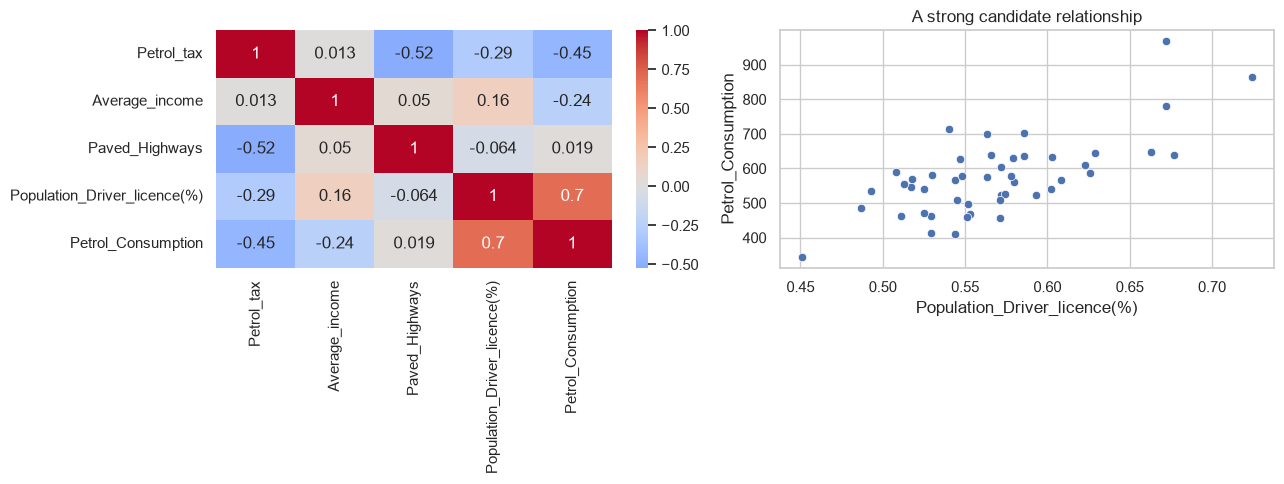

In [5]:
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.heatmap(petrol.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0, ax=axes[0])
sns.scatterplot(data=petrol, x='Population_Driver_licence(%)', y='Petrol_Consumption', ax=axes[1])
axes[1].set_title('A strong candidate relationship')
plt.tight_layout(); plt.show()

## 3. One-feature versus multivariable linear regression

We use one fixed train/test split here only to visualise residuals. Later model selection will use cross-validation.

In [6]:
X_petrol = petrol.drop(columns='Petrol_Consumption')
y_petrol = petrol['Petrol_Consumption']
Xtr, Xte, ytr, yte = train_test_split(X_petrol, y_petrol, test_size=0.25, random_state=RANDOM_STATE)

single_feature = 'Population_Driver_licence(%)'
lin_single = LinearRegression().fit(Xtr[[single_feature]], ytr)
lin_multi = LinearRegression().fit(Xtr, ytr)

p_single = lin_single.predict(Xte[[single_feature]])
p_multi = lin_multi.predict(Xte)

pd.DataFrame([
    {'model':'one feature', **regression_metrics(yte,p_single)},
    {'model':'all four features', **regression_metrics(yte,p_multi)},
]).round(3)

,model,MAE,RMSE,MAPE (%),R2
0,one feature,76.717,84.251,14.893,0.118
1,all four features,57.899,71.693,11.778,0.361


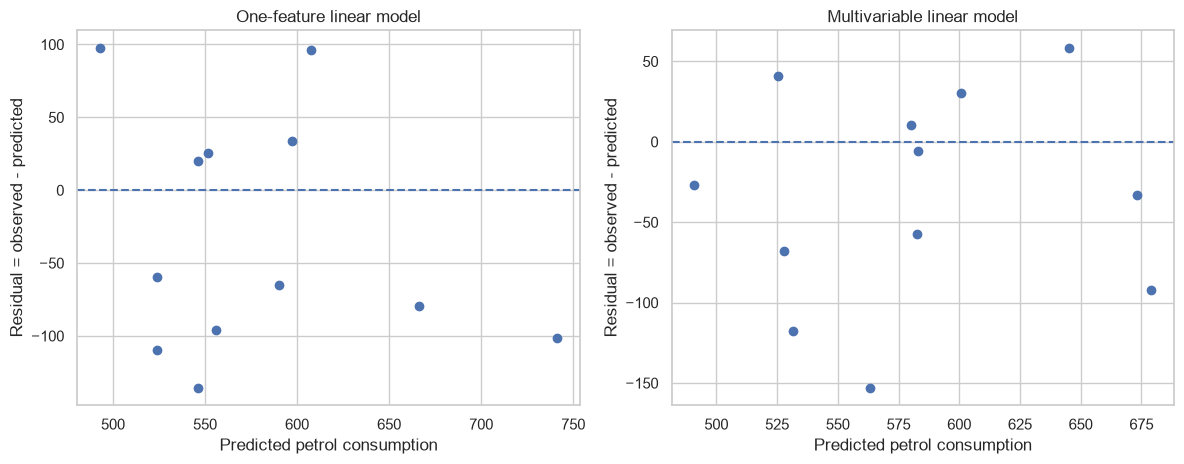

In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4.8))
for ax, name, pred in [
    (axes[0], 'One-feature linear model', p_single),
    (axes[1], 'Multivariable linear model', p_multi),
]:
    residual = yte - pred
    ax.scatter(pred, residual)
    ax.axhline(0, linestyle='--')
    ax.set_xlabel('Predicted petrol consumption')
    ax.set_ylabel('Residual = observed - predicted')
    ax.set_title(name)
plt.tight_layout(); plt.show()

### Activity 2 — Read residuals

1. Which model has lower errors on this split? multivariable linear model
2. Do residuals look randomly scattered around zero? 
3. Identify one observation/model combination with a large residual. multivariable around 563 shows about -153
4. Why is a residual plot evidence that a single aggregate metric cannot provide? same RMSE but different residuals that we can see

## 4. Regularisation: Ridge and Lasso

Linear regression estimates coefficients to minimise squared error. Ridge and Lasso add a penalty:

- **Ridge (L2)** shrinks coefficients smoothly,
- **Lasso (L1)** can shrink some coefficients exactly to zero.

Because the penalty acts on coefficient magnitude, feature scaling matters.

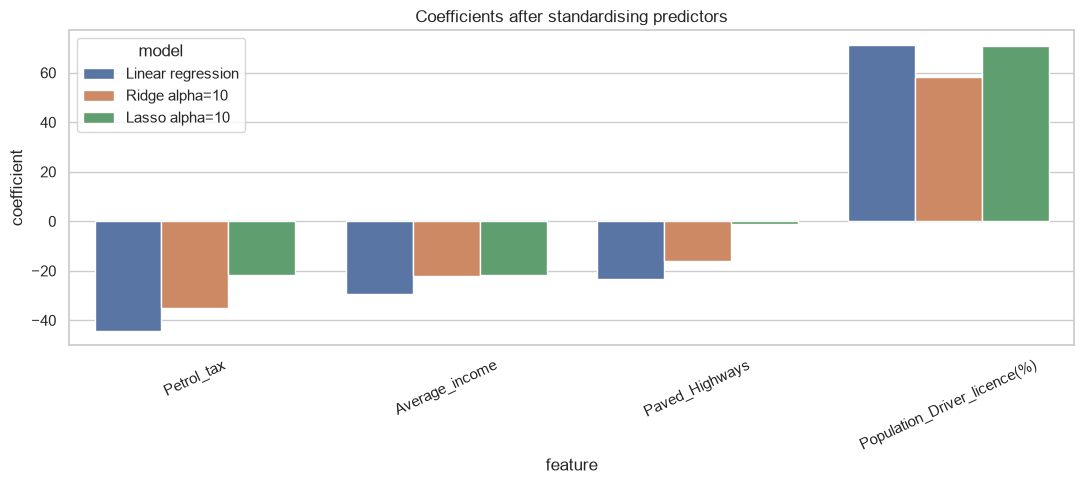

In [8]:
regularised_models = {
    'Linear regression': Pipeline([
        ('scale', StandardScaler()),
        ('model', LinearRegression()),
    ]),
    'Ridge alpha=10': Pipeline([
        ('scale', StandardScaler()),
        ('model', Ridge(alpha=10)),
    ]),
    'Lasso alpha=10': Pipeline([
        ('scale', StandardScaler()),
        ('model', Lasso(alpha=10, max_iter=10000)),
    ]),
}

coef_rows=[]
for name, pipe in regularised_models.items():
    pipe.fit(Xtr,ytr)
    coef = pipe.named_steps['model'].coef_
    for feature,value in zip(Xtr.columns,coef):
        coef_rows.append({'model':name,'feature':feature,'coefficient':value})
coef_df = pd.DataFrame(coef_rows)

plt.figure(figsize=(11,5))
sns.barplot(data=coef_df, x='feature', y='coefficient', hue='model')
plt.xticks(rotation=25)
plt.title('Coefficients after standardising predictors')
plt.tight_layout(); plt.show()

### Activity 3 — Explain regularisation from the coefficients

1. Which method shrinks coefficients most strongly? Lasso
2. Does Lasso set any coefficient close to zero here? Paved_Highways
3. Why would comparing raw coefficient magnitudes before scaling be misleading? Different units would create unfair comparisons. They would get punished more by Ridge and Lasso
4. Why does a smaller coefficient not mean that the feature is scientifically unimportant? Small coefficient only means a feature doesn't add much new information

## 5. Regression versions of familiar model families

Many model ideas previously used for classification also have regression variants. We compare:

- linear regression,
- Ridge,
- Random Forest regression,
- histogram gradient boosting regression.

We use the same 5-fold cross-validation splits for each model.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

petrol_models = {
    'Linear': Pipeline([('scale', StandardScaler()), ('model', LinearRegression())]),
    'Ridge': Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=10))]),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, max_leaf_nodes=7, min_samples_leaf=4, random_state=RANDOM_STATE),
}

scoring = {'MAE':'neg_mean_absolute_error', 'RMSE':'neg_root_mean_squared_error', 'R2':'r2'}
rows=[]
for name,model in petrol_models.items():
    scores = cross_validate(model, X_petrol, y_petrol, cv=cv, scoring=scoring)
    rows.append({
        'model':name,
        'CV MAE':-scores['test_MAE'].mean(),
        'CV RMSE':-scores['test_RMSE'].mean(),
        'CV R2':scores['test_R2'].mean(),
        'R2 std':scores['test_R2'].std(),
    })
petrol_cv = pd.DataFrame(rows).sort_values('CV RMSE')
petrol_cv.round(3)

,model,CV MAE,CV RMSE,CV R2,R2 std
1,Ridge,52.319,65.905,0.534,0.129
0,Linear,54.184,66.831,0.450,0.242
2,Random Forest,54.282,70.636,0.360,0.363
3,Hist Gradient Boosting,56.671,72.359,0.310,0.369


### Activity 4 — Model choice on a small dataset

1. Which model has the best mean RMSE? Ridge
2. Is the ranking identical under MAE and $R^2$? Yes
3. How large is the fold-to-fold variation? 
4. Why should the tiny sample size make you cautious about declaring a universal winner? 

## 6. Dataset 2 — Diabetes

The built-in diabetes dataset has 442 observations and 10 baseline measurements. The target is a quantitative disease-progression measure one year later.

We reuse the same modelling protocol.

In [10]:
diabetes = load_diabetes(as_frame=True)
X_diabetes = diabetes.data
y_diabetes = diabetes.target
print(X_diabetes.shape)
X_diabetes.head()

(442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 7. Dataset 3 — House Prices

House Prices has already appeared earlier in the course. We now reuse its numeric variables for a genuine regression task.

The cell first tries the course dataset URL. If internet access is unavailable, this section can be run later in Colab.

In [11]:
HOUSE_URL = (
    'https://raw.githubusercontent.com/rasvob/'
    'VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/'
    'master/datasets/zsu_cv1_data.csv'
)

house = pd.read_csv(HOUSE_URL)
selected_house_features = [
    'OverallQual','OverallCond','YearBuilt','GrLivArea','LotArea','BedroomAbvGr'
]
X_house = house[selected_house_features].copy()
y_house = house['SalePrice'].copy()
print(X_house.shape)
X_house.head()

(1460, 6)


,OverallQual,OverallCond,YearBuilt,GrLivArea,LotArea,BedroomAbvGr
0,7,5,2003,1710,8450,3
1,6,8,1976,1262,9600,3
2,7,5,2001,1786,11250,3
3,7,5,1915,1717,9550,3
4,8,5,2000,2198,14260,4


## 8. Transfer the same models across three datasets

We define a reusable evaluator. Each dataset keeps its own target scale, so MAE/RMSE values are **not comparable across datasets**. The question is how model rankings and uncertainty change within each dataset.

In [12]:
def compare_regressors(X, y, dataset_name):
    models = {
        'Linear': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', LinearRegression()),
        ]),
        'Ridge': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
            ('model', Ridge(alpha=10)),
        ]),
        'Random Forest': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('model', RandomForestRegressor(
                n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE
            )),
        ]),
        'Hist Gradient Boosting': Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('model', HistGradientBoostingRegressor(
                max_iter=250, learning_rate=0.05, max_leaf_nodes=15,
                min_samples_leaf=5, random_state=RANDOM_STATE
            )),
        ]),
    }
    cv_local = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    result=[]
    for model_name,model in models.items():
        scores = cross_validate(model, X, y, cv=cv_local, scoring=scoring)
        result.append({
            'dataset':dataset_name,
            'model':model_name,
            'MAE':-scores['test_MAE'].mean(),
            'RMSE':-scores['test_RMSE'].mean(),
            'R2':scores['test_R2'].mean(),
            'R2 std':scores['test_R2'].std(),
        })
    return pd.DataFrame(result)

all_results = pd.concat([
    compare_regressors(X_petrol, y_petrol, 'Petrol'),
    compare_regressors(X_diabetes, y_diabetes, 'Diabetes'),
    compare_regressors(X_house, y_house, 'House Prices'),
], ignore_index=True)

all_results.round(3)

,dataset,model,MAE,RMSE,R2,R2 std
0,Petrol,Linear,54.184,66.831,0.450,0.242
1,Petrol,Ridge,52.319,65.905,0.534,0.129
2,Petrol,Random Forest,54.142,70.553,0.363,0.358
3,Petrol,Hist Gradient Boosting,55.078,76.150,0.317,0.236
4,Diabetes,Linear,44.270,54.849,0.478,0.085
5,Diabetes,Ridge,44.286,54.816,0.480,0.082
6,Diabetes,Random Forest,46.646,57.529,0.428,0.094
7,Diabetes,Hist Gradient Boosting,47.367,59.491,0.389,0.091
8,House Prices,Linear,25377.220,39345.124,0.737,0.136
9,House Prices,Ridge,25323.102,39334.291,0.738,0.133


In [13]:
rank_table = all_results.copy()
rank_table['RMSE rank within dataset'] = rank_table.groupby('dataset')['RMSE'].rank(method='min')
rank_table.sort_values(['dataset','RMSE rank within dataset']).round(3)

,dataset,model,MAE,RMSE,R2,R2 std,RMSE rank within dataset
5,Diabetes,Ridge,44.286,54.816,0.480,0.082,1.0
4,Diabetes,Linear,44.270,54.849,0.478,0.085,2.0
6,Diabetes,Random Forest,46.646,57.529,0.428,0.094,3.0
7,Diabetes,Hist Gradient Boosting,47.367,59.491,0.389,0.091,4.0
11,House Prices,Hist Gradient Boosting,20096.627,33343.278,0.802,0.134,1.0
10,House Prices,Random Forest,20988.748,34494.370,0.795,0.116,2.0
9,House Prices,Ridge,25323.102,39334.291,0.738,0.133,3.0
8,House Prices,Linear,25377.220,39345.124,0.737,0.136,4.0
1,Petrol,Ridge,52.319,65.905,0.534,0.129,1.0
0,Petrol,Linear,54.184,66.831,0.450,0.242,2.0


### Activity 5 — What transfers and what does not?

For each dataset identify the best RMSE model, then answer:
Petrol - Ridge, Diabetes - Ridge, House Prices - Hist Gradient Boosting

1. Is one model best on all three datasets? No
2. Where is a linear/regularised model competitive? On smaller or roughly linear datasets
3. Where do nonlinear ensembles help? On larger datasets with strong non-linearities
4. Which dataset has the most unstable $R^2$ across folds? Petrol
5. Why must you not compare a Petrol RMSE numerically with a House Price RMSE? RMSE is measured in units of the target variable

## 9. Target transformation: a useful but consequential choice

House prices are often right-skewed. A log target changes the optimisation emphasis: relative differences become more important than absolute currency differences.

We compare Random Forest on the original target with a log-transformed target wrapper.

In [14]:
rf_plain = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)),
])

rf_log_target = TransformedTargetRegressor(
    regressor=rf_plain,
    func=np.log1p,
    inverse_func=np.expm1,
)

for name,model in [('RF original target',rf_plain), ('RF log1p target',rf_log_target)]:
    scores = cross_validate(model, X_house, y_house, cv=cv, scoring=scoring)
    print(name, {
        'MAE': round(-scores['test_MAE'].mean(),1),
        'RMSE': round(-scores['test_RMSE'].mean(),1),
        'R2': round(scores['test_R2'].mean(),3),
    })

RF original target {'MAE': np.float64(20987.6), 'RMSE': np.float64(34500.1), 'R2': np.float64(0.795)}
RF log1p target {'MAE': np.float64(21115.9), 'RMSE': np.float64(34844.5), 'R2': np.float64(0.793)}


### Activity 6 — Interpret the target transformation

1. Did the transformation improve every metric? No, it made most slightly worse, only R2 improved
2. Why can the answer differ between MAE and RMSE? sensitivity to luxury home outliers
3. What error behaviour is emphasised after a log transform? Relative error instead of absolute dollar error
4. Why should a target transform be chosen for modelling reasons, not only because it improves one number? When relative accuracy matters more then raw currency accuracy

## 10. Guided AI study activity — challenge your metric/model choice

Write your own recommendation for **one** dataset first. Then use:

```text
Act as a regression-method reviewer. Do not choose a model for me and do not rewrite my answer.
Ask me exactly three short questions, one at a time:
1. What real-world error does my chosen metric represent?
2. What residual or cross-validation evidence supports my model choice?
3. Which assumption, uncertainty or alternative model could weaken my conclusion?
Wait for my answer after each question.
```

Close the chat and record only:

**One useful AI question:**  

**One claim I revised:**  

**Evidence used for the revision:**

## 11. Assessed task — Three-dataset regression memo (2 points)

Choose **one** of the three datasets for your main recommendation, but use the other two as comparison context.

Submit:

1. target and practical meaning of the prediction task, 
2. primary metric and why it fits the task, 
3. at least three models compared under the same cross-validation protocol,
4. mean performance and variability,
5. one residual or coefficient/feature observation,
6. recommended model,
7. one reason a different model wins or loses on another dataset,
8. one limitation,
9. optional verified AI note.

### Marking

| Criterion | Points |
|---|---:|
| Metric and validation protocol are appropriate | 0.50 |
| Model comparison uses evidence, not only ranking | 0.50 |
| Recommendation and cross-dataset transfer are reasoned | 0.50 |
| Limitation / uncertainty / verified AI note is meaningful | 0.50 |

### Your regression memo

**Dataset and target:**  House prices, Target: SalePrice

**Primary metric and why:**  RMSE, overvaluating a property carries disproportional financial risk compared to daily valuation noise

**Models compared:**  

**Cross-validation evidence:**  

**Residual / coefficient / feature observation:**  

**Recommendation:**  

**Cross-dataset comparison:**  

**Limitation:**  

**Optional verified AI note:**

# End-of-lab self-check

- [x] I can distinguish MAE, RMSE, MAPE and R².
- [x] I can explain why one metric may matter more in a particular application.
- [x] I inspect residuals rather than trusting one score.
- [x] I can explain L1 and L2 regularisation.
- [x] I know why penalised linear models should usually be fitted after scaling.
- [x] I can name regression counterparts of tree/ensemble classifiers.
- [x] I compare models under the same cross-validation protocol.
- [x] I understand that model rankings can change across datasets.
- [x] I do not compare RMSE values across targets with different units/scales.
- [x] I can explain why a target transformation changes the modelling objective.
- [x] I can defend a regression recommendation with evidence and a limitation.